<a href="https://colab.research.google.com/github/shubhangi-kumari/salary-prediction/blob/main/salary_prediction_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 4: Salary Prediction (Linear Regression)
**Goal:** predict salary from age, gender, education, job title and years of experience, and show that engineered features improve the model.

**Workflow:** Load → Clean → EDA → Feature Engineering → Model → Evaluate

Dataset: [Salary Prediction for Beginners (Kaggle, rkiattisak)](https://www.kaggle.com/datasets/rkiattisak/salary-prediction-for-beginer)

## 1. Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
RARE_THRESHOLD = 5   # job titles appearing fewer times than this become 'Other'
RANDOM_STATE = 42    # same value for every model -> fair comparison

## 2. Load the data
Download `Salary_Data.csv` from the Kaggle link above, then run the cell below and pick the file when prompted.

In [3]:
from google.colab import files
uploaded = files.upload()          # choose Salary_Data.csv
CSV_PATH = next(iter(uploaded))

df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
df.head()

Saving Salary Data.csv to Salary Data.csv
Shape: (375, 6)


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [4]:
df.info()
df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
count,373.000000,373,373,373,373.000000,373.000000
unique,NaN,2,3,174,NaN,NaN
top,NaN,Male,Bachelor's,Director of Marketing,NaN,NaN
freq,NaN,194,224,12,NaN,NaN
mean,37.431635,NaN,NaN,NaN,10.030831,100577.345845
std,7.069073,NaN,NaN,NaN,6.557007,48240.013482
min,23.000000,NaN,NaN,NaN,0.000000,350.000000
25%,31.000000,NaN,NaN,NaN,4.000000,55000.000000
50%,36.000000,NaN,NaN,NaN,9.000000,95000.000000
75%,44.000000,NaN,NaN,NaN,15.000000,140000.000000


## 3. Data cleaning

In [5]:
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
rows_before = len(df)

# Drop rows missing the target or key numeric feature, then any other missing values
df = df.dropna(subset=["Salary", "Years of Experience"])
df = df.dropna(subset=["Age", "Gender", "Education Level", "Job Title"])
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nRows: {rows_before} -> {len(df)}")

# Standardize education labels
def clean_education(x):
    x = str(x).strip().lower()
    if "phd" in x or "doctor" in x: return "PhD"
    if "master" in x:               return "Master's"
    if "bachelor" in x:             return "Bachelor's"
    if "high school" in x:          return "High School"
    return x.title()

df["Education Level"] = df["Education Level"].map(clean_education)
df["Gender"] = df["Gender"].str.strip().str.title()
df["Job Title"] = df["Job Title"].str.strip()

print("\n", df["Education Level"].value_counts())

# Check suspicious low salaries (the minimum was 350)
df[df["Salary"] < 5000]

Missing values:
 Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64 

Duplicate rows: 50

Rows: 375 -> 324

 Education Level
Bachelor's    191
Master's       91
PhD            42
Name: count, dtype: int64


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
248,29.0,Male,Bachelor's,Junior Business Operations Analyst,1.5,350.0


### 3.1 Outlier handling and rare job titles
One record has a salary of 350 for a junior analyst with 1.5 years of experience, which is likely a data-entry error (the next lowest salaries are in the tens of thousands). It is removed so it doesn't distort the regression line.

Job titles are high-cardinality (about 170 unique values), so one-hot encoding them directly would create many sparse columns. The table below shows how many titles and rows are kept at different minimum-count thresholds, so I can choose a sensible cutoff for grouping rare titles into 'Other'.

In [6]:
# Remove the suspicious salary entry
print("Rows before:", len(df))
df = df[df["Salary"] >= 5000].reset_index(drop=True)
print("Rows after removing salary outlier:", len(df))
print("Salary range now:", df["Salary"].min(), "to", df["Salary"].max())

# Check how much data each threshold keeps
c = df["Job Title"].value_counts()
print(f"\nUnique job titles: {len(c)}")
for t in [2, 3, 5, 8]:
    kept = c[c >= t]
    print(f"threshold {t}: {len(kept)} titles kept, "
          f"{kept.sum()/len(df):.0%} of rows keep their own title")

Rows before: 324
Rows after removing salary outlier: 323
Salary range now: 30000.0 to 250000.0

Unique job titles: 174
threshold 2: 67 titles kept, 67% of rows keep their own title
threshold 3: 36 titles kept, 48% of rows keep their own title
threshold 5: 11 titles kept, 22% of rows keep their own title
threshold 8: 3 titles kept, 8% of rows keep their own title


### 3.2 Grouping rare job titles
Job titles appearing fewer than **3 times** are grouped into `'Other'`. This threshold was chosen after comparing options:

| Threshold | Titles kept | Rows keeping own title |
|---|---|---|
| 2 | 67 | 67% |
| 3 | 36 | 48% |
| 5 | 11 | 22% |
| 8 | 3 | 8% |

A threshold of 3 keeps a meaningful share of the job-title information without creating a very large number of sparse one-hot columns relative to the dataset size (~320 rows).

In [7]:
RARE_THRESHOLD = 3

counts = df["Job Title"].value_counts()
rare = counts[counts < RARE_THRESHOLD].index
df["Job Title Grouped"] = df["Job Title"].where(~df["Job Title"].isin(rare), "Other")

print(f"Unique job titles: {df['Job Title'].nunique()} -> {df['Job Title Grouped'].nunique()} after grouping")
print(f"Rows in 'Other': {(df['Job Title Grouped'] == 'Other').mean():.0%}")
print("\nTop grouped categories:")
print(df["Job Title Grouped"].value_counts().head(10))

df.to_csv("salary_cleaned.csv", index=False)   # cleaned dataset deliverable
print("\nSaved salary_cleaned.csv, shape:", df.shape)

Unique job titles: 174 -> 37 after grouping
Rows in 'Other': 52%

Top grouped categories:
Job Title Grouped
Other                        169
Director of Operations         9
Director of Marketing          8
Senior Marketing Manager       8
Senior Project Manager         7
Senior Financial Analyst       6
Senior Business Analyst        6
Junior Financial Analyst       6
Senior Data Scientist          6
Senior Operations Manager      5
Name: count, dtype: int64

Saved salary_cleaned.csv, shape: (323, 7)


## 4. Exploratory data analysis
Four visualizations to understand the salary distribution and what drives it:
1. Distribution of salary
2. Average salary by education level and gender
3. Years of experience vs salary
4. Top 10 highest-paying job titles (excluding the 'Other' group)

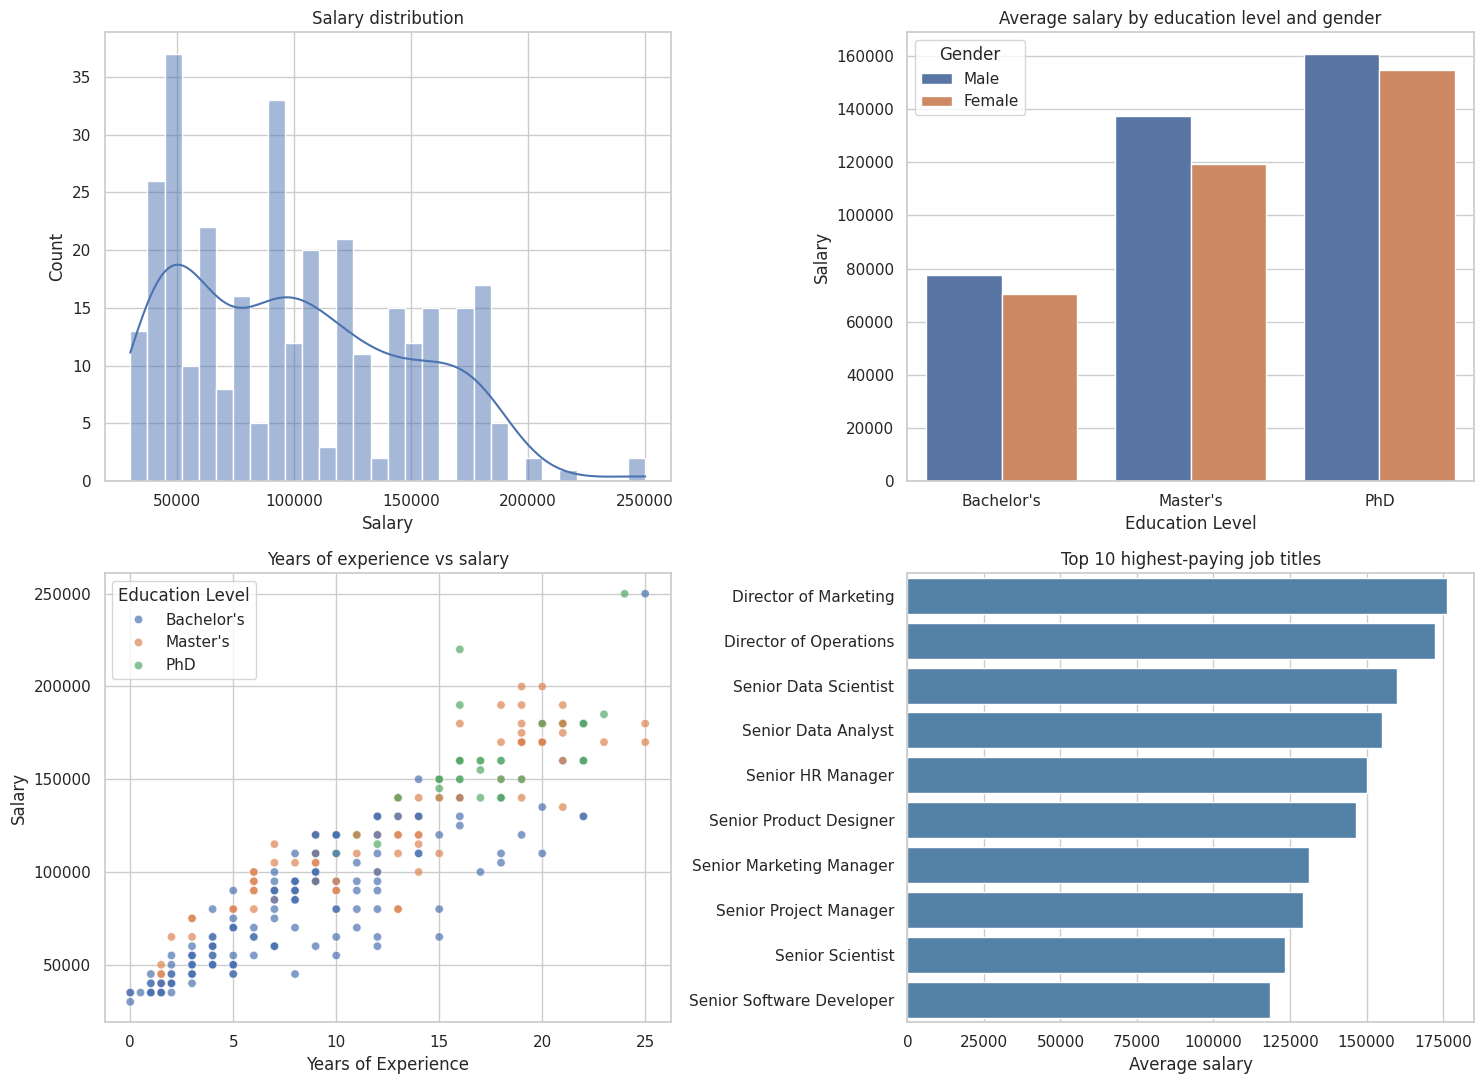

Salary skew: 0.45

Average salary by education:
 Education Level
Bachelor's     74289.0
Master's      127912.0
PhD           158095.0
Name: Salary, dtype: float64

Average salary by gender:
 Gender
Female     96136.0
Male      104083.0
Name: Salary, dtype: float64

Correlations with Salary:
 Age                    0.917
Years of Experience    0.925
Salary                 1.000
Name: Salary, dtype: float64

Top 10 job titles:
 Job Title Grouped
Director of Marketing        176250.0
Director of Operations       172222.0
Senior Data Scientist        160000.0
Senior Data Analyst          155000.0
Senior HR Manager            150000.0
Senior Product Designer      146667.0
Senior Marketing Manager     131250.0
Senior Project Manager       129286.0
Senior Scientist             123333.0
Senior Software Developer    118333.0
Name: Salary, dtype: float64


In [8]:
import os
os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Salary distribution
sns.histplot(df["Salary"], bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Salary distribution")

# 2. Average salary by education and gender
sns.barplot(data=df, x="Education Level", y="Salary", hue="Gender",
            order=["Bachelor's", "Master's", "PhD"], errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("Average salary by education level and gender")

# 3. Experience vs salary
sns.scatterplot(data=df, x="Years of Experience", y="Salary", hue="Education Level", alpha=0.7, ax=axes[1, 0])
axes[1, 0].set_title("Years of experience vs salary")

# 4. Top 10 highest-paying job titles
top_titles = (df[df["Job Title Grouped"] != "Other"]
              .groupby("Job Title Grouped")["Salary"].mean()
              .sort_values(ascending=False).head(10))
sns.barplot(x=top_titles.values, y=top_titles.index, color="steelblue", ax=axes[1, 1])
axes[1, 1].set_xlabel("Average salary")
axes[1, 1].set_ylabel("")
axes[1, 1].set_title("Top 10 highest-paying job titles")

plt.tight_layout()
plt.savefig("figures/eda_overview.png", dpi=150)
plt.show()

# Numbers behind the plots
print("Salary skew:", round(df["Salary"].skew(), 2))
print("\nAverage salary by education:\n", df.groupby("Education Level")["Salary"].mean().round(0))
print("\nAverage salary by gender:\n", df.groupby("Gender")["Salary"].mean().round(0))
print("\nCorrelations with Salary:\n", df[["Age", "Years of Experience", "Salary"]].corr()["Salary"].round(3))
print("\nTop 10 job titles:\n", top_titles.round(0))

### EDA observations
- **Salary distribution:** ranges from about 30k to 250k, slightly right-skewed (skew = 0.45) with most salaries between 40k and 190k. No extreme outliers remain after removing the 350 entry.
- **Education:** average salary rises sharply with education: Bachelor's ≈ 74k, Master's ≈ 128k, PhD ≈ 158k.
- **Gender:** the average salary is about 8k higher for men (≈104k vs ≈96k). This is a raw difference, not adjusted for experience, education or job title, so it should not be read as proof of pay discrimination. It does show why the model should be used carefully in compensation decisions (see bias note in the README).
- **Experience:** salary increases roughly linearly with years of experience (correlation 0.925), and the PhD/Master's points sit above Bachelor's at the same experience level. A linear model should therefore already perform well.
- **Age vs experience:** Age and Years of Experience are both strongly correlated with salary (0.917 and 0.925) and with each other, so they carry overlapping information.
- **Job titles:** the highest-paying titles are Directors and Senior roles. Several of these titles appear only 3 to 9 times, so their averages are based on very few people.

## 5. Feature engineering
Two new features are created:

| Feature | Definition | Why it might help |
|---|---|---|
| `experience_level` | Entry (≤ 3 years), Mid (3–10 years), Senior (> 10 years) | Gives each career stage its own salary offset |
| `age_experience_ratio` | Age / (Years of Experience + 1) | Separates people who worked their whole career from late starters or career changers of the same age |

The `+ 1` avoids division by zero for candidates with 0 years of experience. Gender, Education Level, grouped Job Title and `experience_level` are one-hot encoded (first category dropped to avoid redundant columns).

In [10]:
# experience_level bucket
df["experience_level"] = pd.cut(
    df["Years of Experience"], bins=[-np.inf, 3, 10, np.inf],
    labels=["Entry", "Mid", "Senior"]
).astype(str)

# age_experience_ratio
df["age_experience_ratio"] = df["Age"] / (df["Years of Experience"] + 1)

# Do the new features carry signal?
print(df["experience_level"].value_counts())
print("\nAverage salary by experience level:\n", df.groupby("experience_level")["Salary"].mean().round(0))
print("\nCorrelation of age_experience_ratio with Salary:",
      round(df["age_experience_ratio"].corr(df["Salary"]), 3))
print("Correlation between Age and Years of Experience:",
      round(df["Age"].corr(df["Years of Experience"]), 3))

# One-hot encode categoricals
encoded = pd.get_dummies(
    df[["Gender", "Education Level", "Job Title Grouped", "experience_level"]],
    drop_first=True, dtype=float)

X_all = pd.concat([df[["Age", "Years of Experience", "age_experience_ratio"]], encoded], axis=1)
y = df["Salary"]

# Column groups for the baseline vs engineered models
exp_cols  = [c for c in X_all.columns if c.startswith("experience_level_")]
base_cols = [c for c in X_all.columns if c not in exp_cols and c != "age_experience_ratio"]

print(f"\nTotal columns: {X_all.shape[1]}")
print(f"Baseline features: {len(base_cols)} | experience_level columns: {len(exp_cols)} | ratio: 1")

experience_level
Senior    138
Mid       111
Entry      74
Name: count, dtype: int64

Average salary by experience level:
 experience_level
Entry      44324.0
Mid        83198.0
Senior    144058.0
Name: Salary, dtype: float64

Correlation of age_experience_ratio with Salary: -0.719
Correlation between Age and Years of Experience: 0.979

Total columns: 44
Baseline features: 41 | experience_level columns: 2 | ratio: 1


## 6. Model building
A **single train/test split (80/20, `random_state=42`)** is shared by every model, so the comparison is fair. Four Linear Regression models are trained:

| Model | Features |
|---|---|
| Baseline | Age, Years of Experience, Gender, Education, grouped Job Title |
| + experience_level | Baseline + experience_level buckets |
| + age_experience_ratio | Baseline + age_experience_ratio |
| + Both (engineered) | Baseline + both new features |

Testing each feature on its own shows which one helped most. Train R² is reported next to test R² to check for overfitting.

In [11]:
idx_train, idx_test = train_test_split(df.index, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train rows: {len(idx_train)} | Test rows: {len(idx_test)}")

def evaluate(cols, name):
    model = LinearRegression().fit(X_all.loc[idx_train, cols], y.loc[idx_train])
    pred_test = model.predict(X_all.loc[idx_test, cols])
    pred_train = model.predict(X_all.loc[idx_train, cols])
    yt = y.loc[idx_test]
    return {"Model": name,
            "Features": len(cols),
            "Train R2": r2_score(y.loc[idx_train], pred_train),
            "Test R2": r2_score(yt, pred_test),
            "MAE": mean_absolute_error(yt, pred_test),
            "RMSE": np.sqrt(mean_squared_error(yt, pred_test))}, pred_test

variants = {
    "Baseline": base_cols,
    "+ experience_level": base_cols + exp_cols,
    "+ age_experience_ratio": base_cols + ["age_experience_ratio"],
    "+ Both (engineered)": base_cols + exp_cols + ["age_experience_ratio"],
}

rows, preds = [], {}
for name, cols in variants.items():
    m, p = evaluate(cols, name)
    rows.append(m)
    preds[name] = p

metrics = pd.DataFrame(rows).set_index("Model")
metrics["Test R2 change vs baseline"] = metrics["Test R2"] - metrics.loc["Baseline", "Test R2"]
metrics.round(4)

Train rows: 258 | Test rows: 65


,Features,Train R2,Test R2,MAE,RMSE,Test R2 change vs baseline
Model,,,,,,
Baseline,41,0.9140,0.8847,11038.8831,15015.7036,0.0000
+ experience_level,43,0.9153,0.8885,10876.2602,14764.3218,0.0038
+ age_experience_ratio,42,0.9148,0.8810,11356.3301,15256.9387,-0.0037
+ Both (engineered),44,0.9159,0.8867,11194.3532,14884.5045,0.0020


## 7. Evaluation
R², MAE and RMSE on the held-out test set (65 rows) for each model. The bar chart compares test R² before and after feature engineering, and the scatter plot shows predicted vs actual salary for the best-performing model.

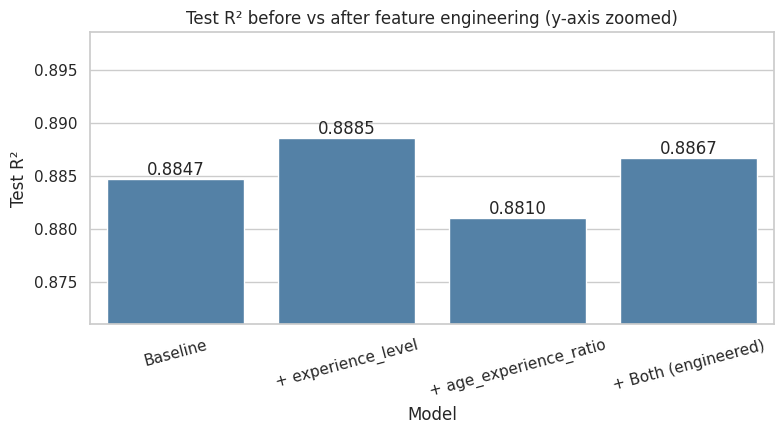

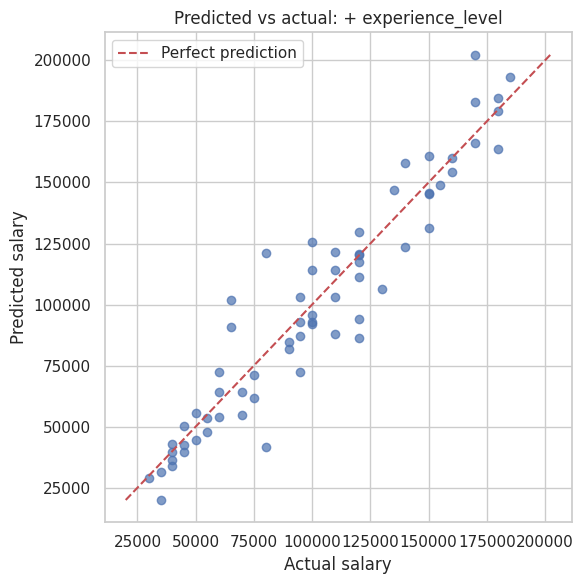

Best model by test R2: + experience_level
Largest single-feature gain: + experience_level (R2 +0.0038)
Both features together: R2 +0.0020


In [12]:
# R2 comparison bar chart (zoomed so small differences are visible)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=metrics.index, y=metrics["Test R2"], color="steelblue", ax=ax)
ax.bar_label(ax.containers[0], fmt="%.4f")
ax.set_ylim(metrics["Test R2"].min() - 0.01, metrics["Test R2"].max() + 0.01)
ax.set_ylabel("Test R²")
ax.set_title("Test R² before vs after feature engineering (y-axis zoomed)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("figures/r2_comparison.png", dpi=150)
plt.show()

# Predicted vs actual for the best model
best = metrics["Test R2"].idxmax()
yt = y.loc[idx_test]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(yt, preds[best], alpha=0.7)
lim = [min(yt.min(), preds[best].min()), max(yt.max(), preds[best].max())]
ax.plot(lim, lim, "r--", label="Perfect prediction")
ax.set_xlabel("Actual salary")
ax.set_ylabel("Predicted salary")
ax.set_title(f"Predicted vs actual: {best}")
ax.legend()
plt.tight_layout()
plt.savefig("figures/predicted_vs_actual.png", dpi=150)
plt.show()

# Summary lines for the README
gains = metrics.loc[["+ experience_level", "+ age_experience_ratio"], "Test R2 change vs baseline"]
print(f"Best model by test R2: {best}")
print(f"Largest single-feature gain: {gains.idxmax()} (R2 {gains.max():+.4f})")
print(f"Both features together: R2 {metrics.loc['+ Both (engineered)', 'Test R2 change vs baseline']:+.4f}")
metrics.round(4).to_csv("metrics_comparison.csv")